# Part II — Explanatory Analysis: Understanding Bay Area Bike-Sharing Patterns

## Who Rides, When, and How Long

This presentation distills the key findings from the exploratory analysis of the Ford GoBike System dataset (February 2019, 183,412 trips). We focus on three core findings that reveal distinct user personas and temporal patterns.


In [1]:
# Setup: imports and data preparation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams.update({'figure.figsize': (10, 6), 'font.size': 12,
                     'axes.titlesize': 15, 'axes.labelsize': 13})

def format_plot(ax, title, xlabel, ylabel):
    """Apply polished formatting to a matplotlib axes object."""
    ax.set_title(title, fontsize=15, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel, fontsize=13)
    ax.set_ylabel(ylabel, fontsize=13)
    ax.tick_params(labelsize=11)
    sns.despine(ax=ax)
    return ax


## Dataset Overview

**Source:** Ford GoBike System (now Bay Wheels), February 2019  
**Size:** 183,412 trip records  
**Key variables:** trip duration, start/end timestamps, station locations, user type (Subscriber / Customer), rider demographics

After cleaning (removing missing values, extreme durations > 60 min, implausible ages), approximately 174,000 trips remain for analysis.


In [2]:
# Load and prepare data (same wrangling as Part I)
df = pd.read_csv('201902-fordgobike-tripdata.csv')
df['start_time'] = pd.to_datetime(df['start_time'])
df['duration_min'] = df['duration_sec'] / 60
df['hour'] = df['start_time'].dt.hour
df['age'] = 2019 - df['member_birth_year']

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_of_week'] = pd.Categorical(df['start_time'].dt.day_name(), categories=day_order, ordered=True)

# Clean
df = df.dropna(subset=['member_gender', 'member_birth_year'])
df = df[(df['duration_min'] > 0) & (df['duration_min'] <= 60)]
df = df[(df['age'] >= 16) & (df['age'] <= 80)]

print(f"Clean dataset: {len(df):,} trips")


Clean dataset: 173,565 trips


## Finding 1: Most Trips Are Short — A Log-Normal Duration Distribution

The vast majority of bike-share trips last between **5 and 15 minutes**, with a median of roughly 9 minutes. The distribution is strongly right-skewed, requiring a log scale to visualize properly. This is consistent with a system used primarily for **short urban commutes** and last-mile connections.


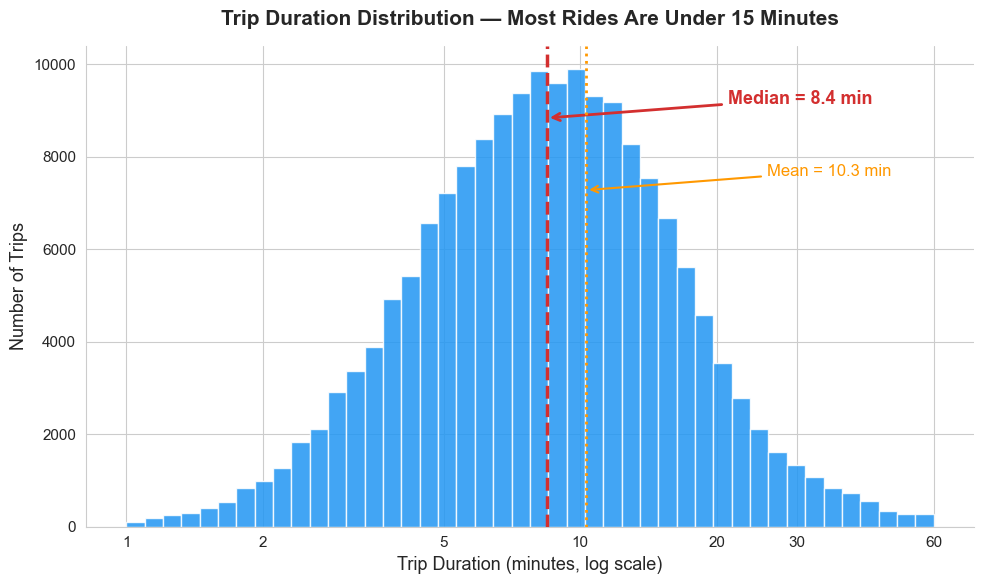

In [3]:
# EXPLANATORY PLOT 1: Polished histogram of trip duration
fig, ax = plt.subplots(figsize=(10, 6))

# Log-spaced bins for the skewed distribution
log_bins = np.logspace(np.log10(1), np.log10(60), 45)
ax.hist(df['duration_min'], bins=log_bins, edgecolor='white', color='#2196F3', alpha=0.85)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(ticker.ScalarFormatter())
ax.set_xticks([1, 2, 5, 10, 20, 30, 60])

# Median annotation
median_val = df['duration_min'].median()
ax.axvline(median_val, color='#D32F2F', linestyle='--', linewidth=2.5, zorder=5)
ax.annotate(f'Median = {median_val:.1f} min',
            xy=(median_val, ax.get_ylim()[1] * 0.85),
            xytext=(median_val * 2.5, ax.get_ylim()[1] * 0.88),
            fontsize=13, fontweight='bold', color='#D32F2F',
            arrowprops=dict(arrowstyle='->', color='#D32F2F', lw=2))

# Mean annotation
mean_val = df['duration_min'].mean()
ax.axvline(mean_val, color='#FF9800', linestyle=':', linewidth=2, zorder=5)
ax.annotate(f'Mean = {mean_val:.1f} min',
            xy=(mean_val, ax.get_ylim()[1] * 0.70),
            xytext=(mean_val * 2.5, ax.get_ylim()[1] * 0.73),
            fontsize=12, color='#FF9800',
            arrowprops=dict(arrowstyle='->', color='#FF9800', lw=1.5))

format_plot(ax, 'Trip Duration Distribution — Most Rides Are Under 15 Minutes',
            'Trip Duration (minutes, log scale)', 'Number of Trips')

plt.tight_layout()
plt.show()


## Finding 2: Weekday Commute Peaks Dominate Usage

The system shows a textbook **bimodal commuter pattern** on weekdays, with peaks at **8–9 AM** (morning commute) and **5–6 PM** (evening commute). Weekends show a completely different pattern — a single broad midday plateau. This confirms that the Bay Area bike-share system functions primarily as **transit infrastructure** during the work week.


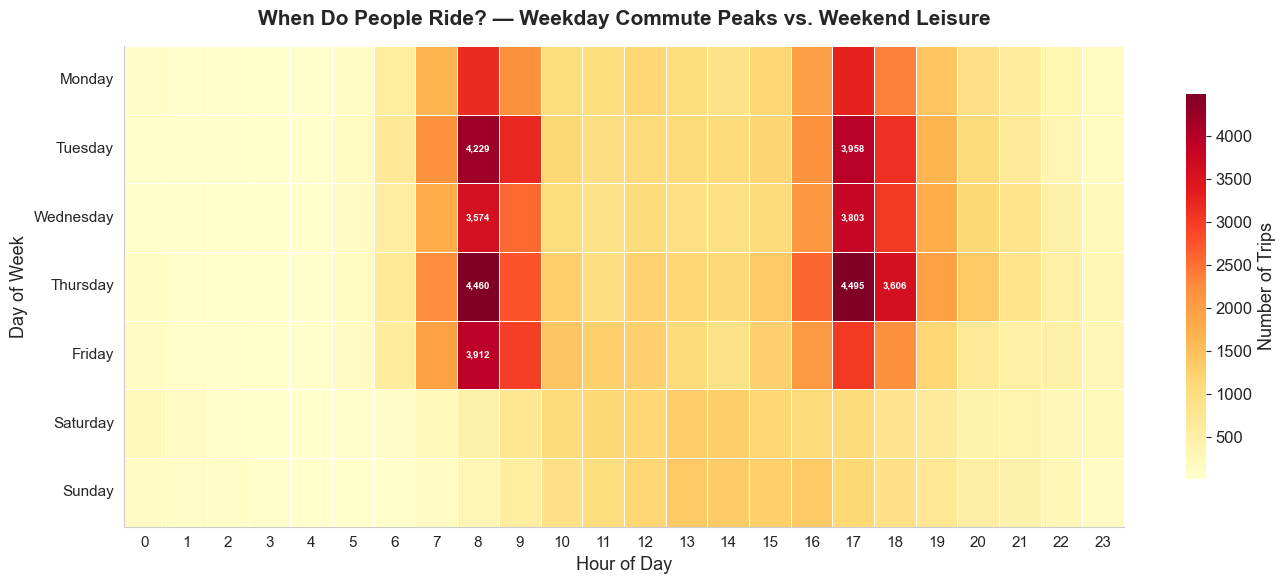

In [4]:
# EXPLANATORY PLOT 2: Polished heatmap of trips by hour x day_of_week
fig, ax = plt.subplots(figsize=(14, 6))

# Build pivot table
pivot = df.groupby(['day_of_week', 'hour']).size().unstack(fill_value=0)

# Custom colormap for better readability
sns.heatmap(pivot, cmap='YlOrRd', linewidths=0.4, linecolor='white',
            cbar_kws={'label': 'Number of Trips', 'shrink': 0.8},
            ax=ax, fmt=',')

# Annotate the peak cells
max_val = pivot.max().max()
for day_idx, day in enumerate(pivot.index):
    for hour in pivot.columns:
        val = pivot.loc[day, hour]
        if val > max_val * 0.75:  # highlight top 25% cells
            ax.text(hour + 0.5, day_idx + 0.5, f'{val:,}',
                    ha='center', va='center', fontsize=7, fontweight='bold', color='white')

format_plot(ax, 'When Do People Ride? — Weekday Commute Peaks vs. Weekend Leisure',
            'Hour of Day', '')
ax.set_ylabel('Day of Week', fontsize=13)

plt.tight_layout()
plt.show()


## Finding 3: Two Distinct User Personas — Commuters vs. Explorers

Subscribers and Customers use the system in fundamentally different ways:

- **Subscribers** (~90% of trips): Short, routine rides concentrated during rush hours. Their behavior is remarkably consistent across weekdays.
- **Customers** (~10% of trips): Longer, more variable rides peaking in the afternoon. They ride more on weekends, suggesting leisure or tourist usage.

The chart below overlays their hourly patterns, revealing how Subscribers create the commute peaks while Customers prefer the afternoon.


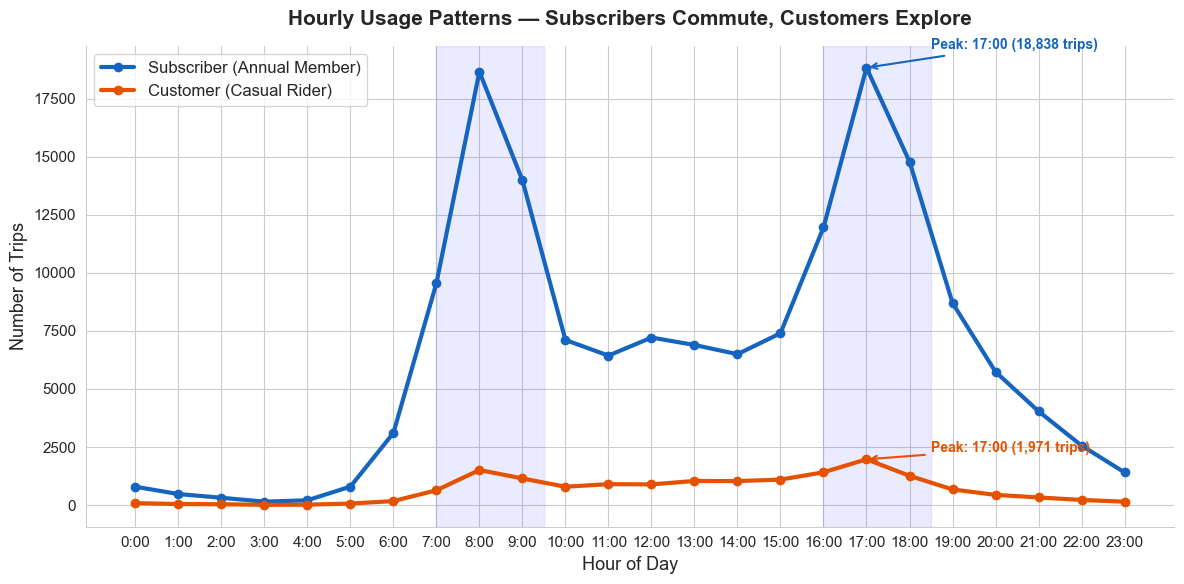

In [5]:
# EXPLANATORY PLOT 3: Polished grouped line chart — hourly patterns by user type
fig, ax = plt.subplots(figsize=(12, 6))

colors = {'Subscriber': '#1565C0', 'Customer': '#E65100'}
labels = {'Subscriber': 'Subscriber (Annual Member)', 'Customer': 'Customer (Casual Rider)'}

for utype in ['Subscriber', 'Customer']:
    subset = df[df['user_type'] == utype]
    hourly = subset.groupby('hour').size()
    ax.plot(hourly.index, hourly.values, marker='o', linewidth=3,
            color=colors[utype], label=labels[utype], markersize=6)
    
    # Annotate peak
    peak_hour = hourly.idxmax()
    peak_val = hourly.max()
    offset_y = 800 if utype == 'Subscriber' else 300
    ax.annotate(f'Peak: {peak_hour}:00 ({peak_val:,} trips)',
                xy=(peak_hour, peak_val),
                xytext=(peak_hour + 1.5, peak_val + offset_y),
                fontsize=10, color=colors[utype], fontweight='bold',
                arrowprops=dict(arrowstyle='->', color=colors[utype], lw=1.5))

ax.set_xticks(range(0, 24))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{int(x)}:00'))
format_plot(ax, 'Hourly Usage Patterns — Subscribers Commute, Customers Explore',
            'Hour of Day', 'Number of Trips')
ax.legend(fontsize=12, loc='upper left')

# Shade commute hours
for start, end in [(7, 9.5), (16, 18.5)]:
    ax.axvspan(start, end, alpha=0.08, color='blue', label='_nolegend_')

plt.tight_layout()
plt.show()


## Finding 4: Subscribers Ride Shorter and More Consistently

The box plot below directly compares trip duration between the two user types. Subscribers' trips are tightly concentrated around 8–10 minutes, while Customers show a wider range with a higher median (~12 minutes). This reinforces the commuter vs. explorer dichotomy.


/var/folders/8k/rsg3bc7s5qd3v07_19wz50rc0000gn/T/ipykernel_95328/3019102920.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bp = sns.boxplot(x='user_type', y='duration_min', data=df, ax=ax,


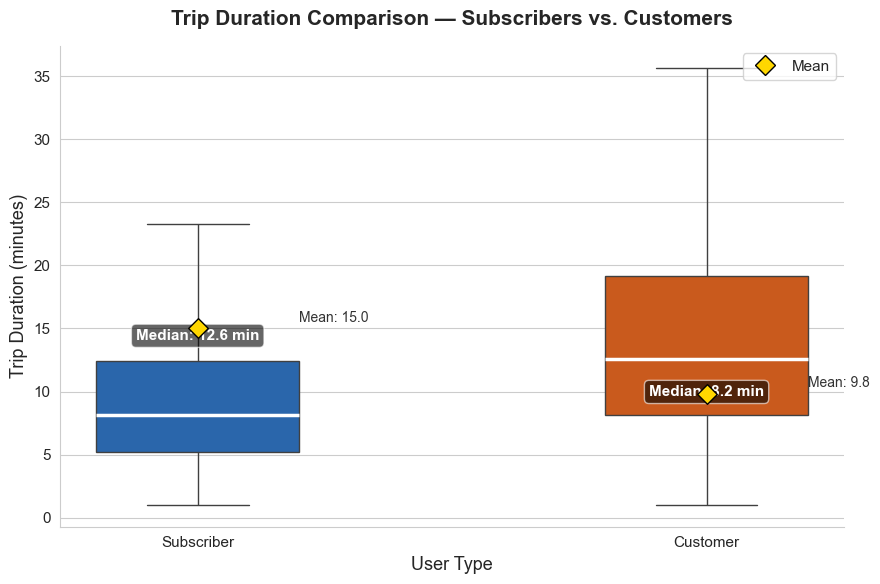

In [6]:
# EXPLANATORY PLOT 4: Polished box plot — duration by user type with annotations
fig, ax = plt.subplots(figsize=(9, 6))

# Use seaborn for better aesthetics
bp = sns.boxplot(x='user_type', y='duration_min', data=df, ax=ax,
                 palette={'Subscriber': '#1565C0', 'Customer': '#E65100'},
                 width=0.4, showfliers=False,
                 medianprops=dict(color='white', linewidth=2.5))

# Annotate medians and means
for i, utype in enumerate(['Customer', 'Subscriber']):
    subset = df[df['user_type'] == utype]['duration_min']
    med = subset.median()
    mean = subset.mean()
    ax.text(i, med + 1.5, f'Median: {med:.1f} min', ha='center',
            fontsize=11, fontweight='bold', color='white',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.6))
    ax.scatter(i, mean, marker='D', s=100, color='gold', zorder=5, edgecolors='black')
    ax.text(i + 0.2, mean + 0.5, f'Mean: {mean:.1f}', fontsize=10, color='#333')

format_plot(ax, 'Trip Duration Comparison — Subscribers vs. Customers',
            'User Type', 'Trip Duration (minutes)')

# Add legend for diamond marker
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='D', color='w', markerfacecolor='gold',
                          markeredgecolor='black', markersize=10, label='Mean')]
ax.legend(handles=legend_elements, fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()


## Summary

The Ford GoBike System in February 2019 reveals a **dual-purpose transportation network**:

1. **Short trips dominate** — the median ride is ~9 minutes, following a log-normal distribution. The system serves as a "last mile" connector for urban transit.

2. **Temporal patterns tell a clear story** — weekday commute peaks (8 AM, 5 PM) contrast sharply with diffuse weekend leisure usage. The heatmap makes this immediately visible.

3. **Two user personas emerge** — Subscribers are routine commuters (short, consistent, rush-hour rides), while Customers are explorers (longer, variable, afternoon/weekend rides). This distinction was the strongest signal across all visualizations.

These insights can inform **bike redistribution strategies** (stock stations before rush hours), **pricing models** (different rates for commuters vs. tourists), and **infrastructure planning** (prioritize routes between transit hubs for commuters, scenic routes for leisure riders).
